# **Import libraries & read datas**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [6]:
df1 = pd.read_csv(r"C:\Users\Lenovo\Desktop\final\run1\full_preprocessed_run1.csv")
df2 = pd.read_csv(r"C:\Users\Lenovo\Desktop\final\run2\full_preprocessed_run2.csv")
df3 = pd.read_csv(r"C:\Users\Lenovo\Desktop\final\run3\full_preprocessed_run3.csv")
superdata = pd.concat([df1,df2,df3],ignore_index = True)
superdata.to_csv("allrun10.csv")

In [5]:
superdata

,Frame #,Residue,Residue Number,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL
0,50000,R::THR,630,0.0,0.0,-0.02,0.02,0.0,0.00
1,50000,R::ALA,631,0.0,0.0,-0.01,0.01,0.0,0.00
2,50000,R::GLY,632,0.0,0.0,-0.01,0.01,0.0,-0.00
3,50000,R::ASN,633,0.0,0.0,-0.01,0.02,0.0,0.00
4,50000,R::GLU,634,0.0,0.0,0.03,-0.03,0.0,0.01
...,...,...,...,...,...,...,...,...,...
13500265,100000,L::H2O2,717,0.0,0.0,0.02,-0.03,0.0,-0.00
13500266,100000,L::H2O2,718,0.0,-0.0,0.12,-0.10,0.0,0.01
13500267,100000,L::H2O2,719,0.0,0.0,-0.00,0.00,0.0,0.00
13500268,100000,L::H2O2,720,0.0,0.0,0.30,-0.29,0.0,0.01


In [6]:
def filter(data_name):
    data_name =data_name[~data_name['Residue'].str.contains('L::H2O2', case=False, na=False)]
    data_name =data_name[~data_name['Residue'].str.contains('L::H', case=False, na=False)]
    data_name['Residue']=data_name['Residue'].str.replace('R::','',regex=False)
    data_name['Residue']=data_name['Residue'].str.replace(':','',regex=False)
    data_name['Residue']=data_name['Residue'].str.replace('::','',regex=False)
    filtered_data_name=data_name[(data_name['TOTAL']<-0.1)|(data_name['TOTAL']>0.1)]
    return filtered_data_name
filter(df1)


,Frame #,Residue,Residue Number,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL
3244,50036,GLU,634,0.0,-0.03,1.21,-1.03,-0.03,0.12
41192,50457,ILE,692,0.0,-0.04,0.08,-0.07,-0.09,-0.12
41282,50458,ILE,692,0.0,-0.05,0.03,-0.02,-0.10,-0.13
41372,50459,ILE,692,0.0,-0.33,-0.02,0.08,-0.21,-0.48
41462,50460,ILE,692,0.0,-0.32,0.04,0.09,-0.22,-0.41
...,...,...,...,...,...,...,...,...,...
4458733,99541,ARG,673,0.0,-0.09,-1.03,1.09,-0.09,-0.12
4458823,99542,ARG,673,0.0,-0.10,-0.91,0.97,-0.10,-0.14
4458913,99543,ARG,673,0.0,-0.12,-0.93,0.98,-0.11,-0.18
4459093,99545,ARG,673,0.0,-0.08,-0.53,0.57,-0.07,-0.11


In [7]:
superdata['Residue'].value_counts()

Residue
R::SER     1950039
L::H2O2    1500030
R::GLU     1350027
R::ARG     1200024
R::LEU     1050021
R::ALA      900018
R::ASP      750015
R::LYS      750015
R::ASN      600012
R::ILE      600012
R::THR      600012
R::VAL      450009
R::PRO      450009
R::MET      300006
R::GLY      300006
R::GLN      300006
R::TRP      300006
R::PHE      150003
Name: count, dtype: int64

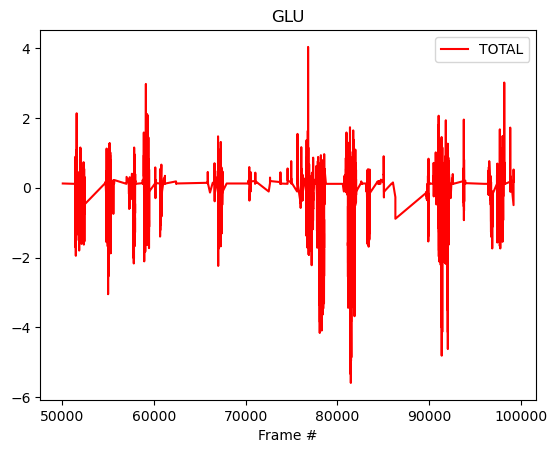

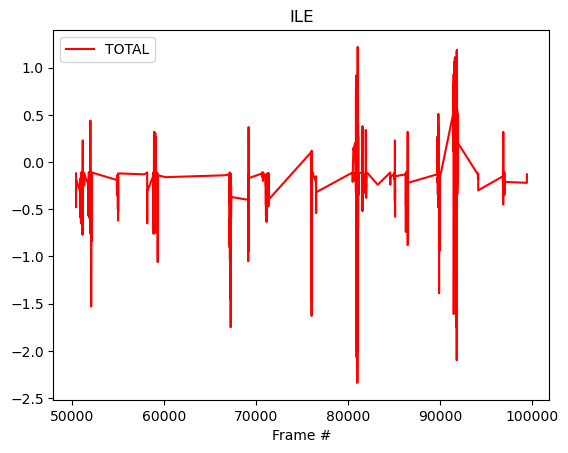

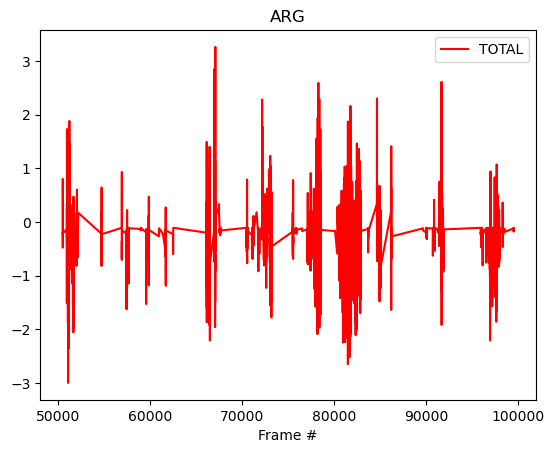

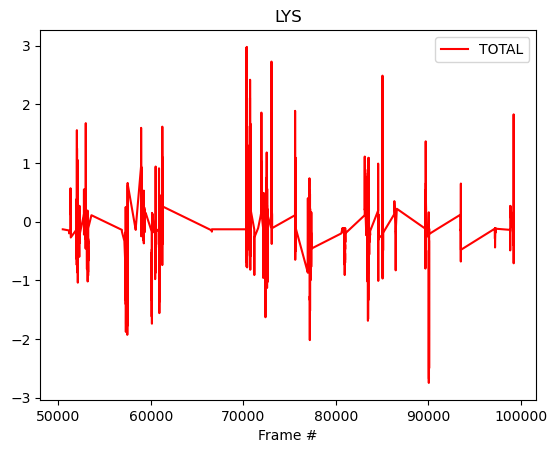

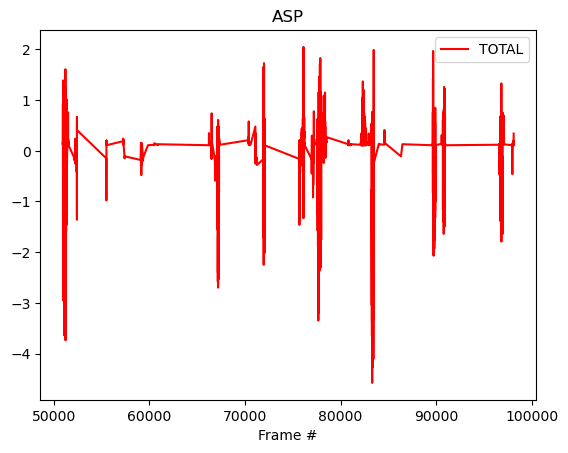

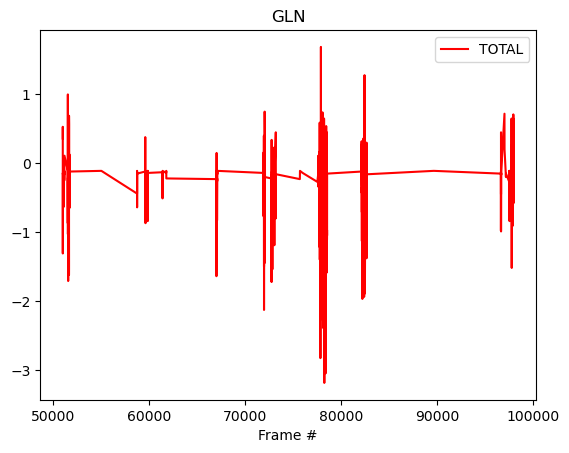

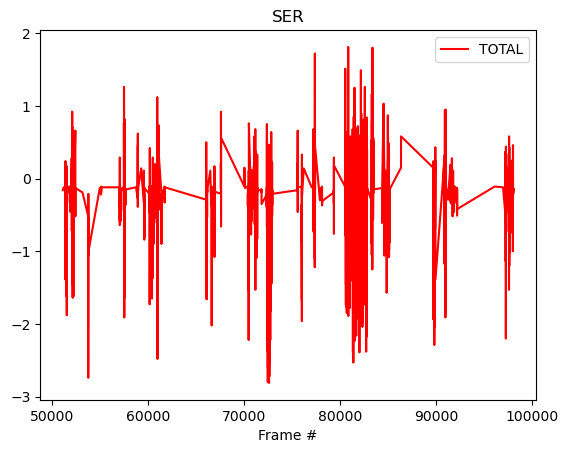

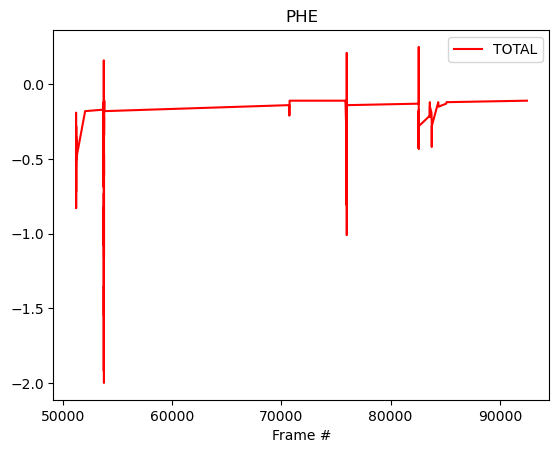

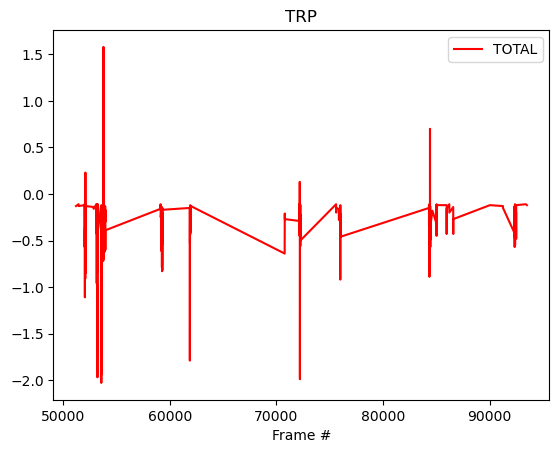

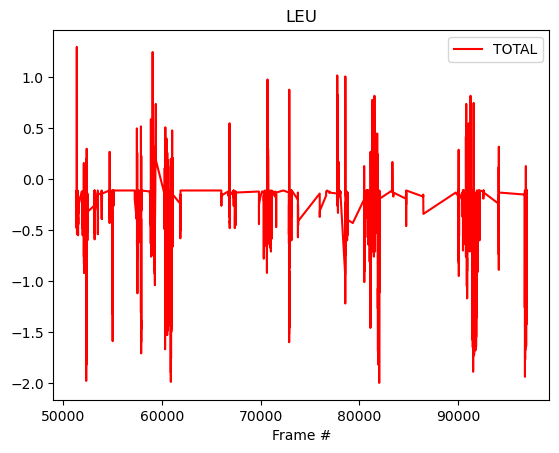

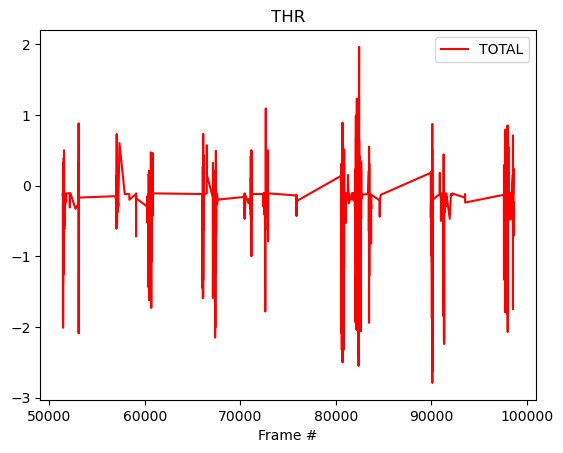

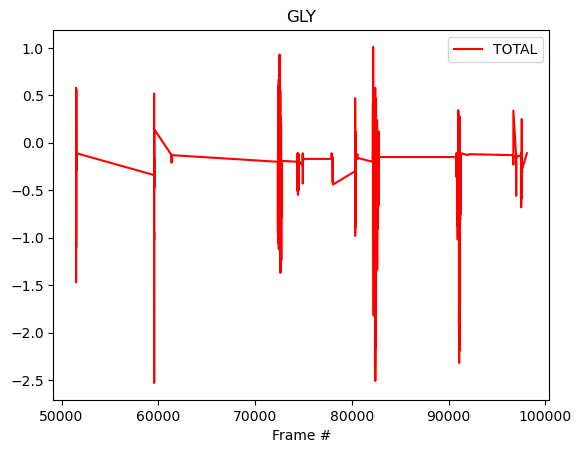

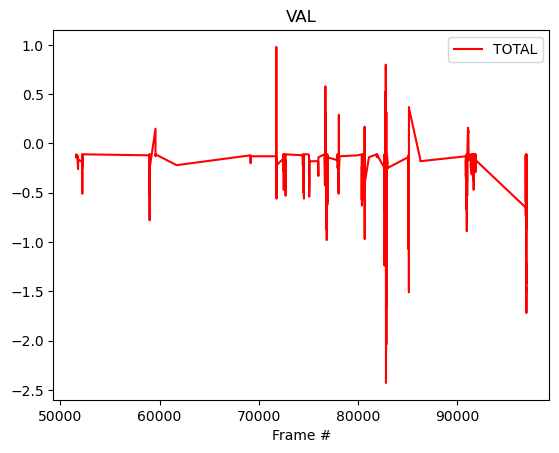

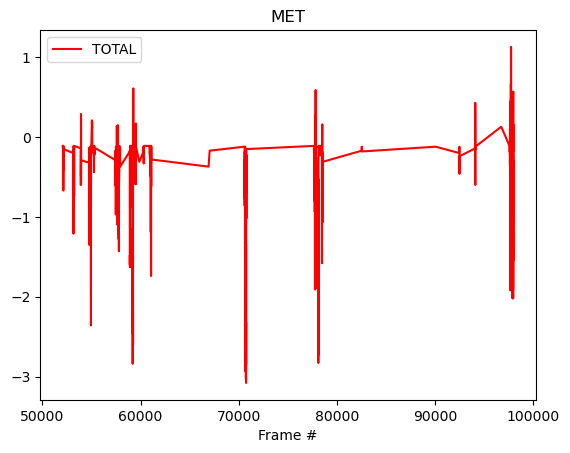

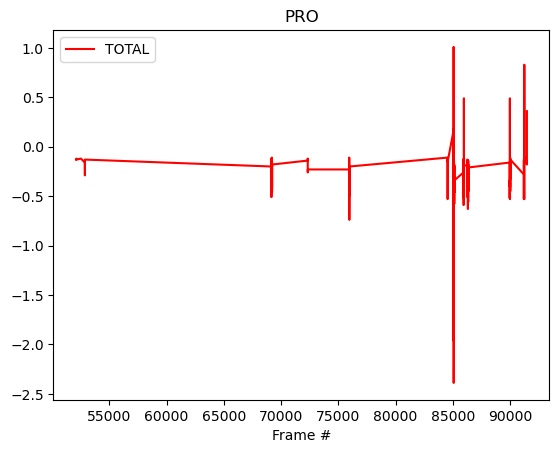

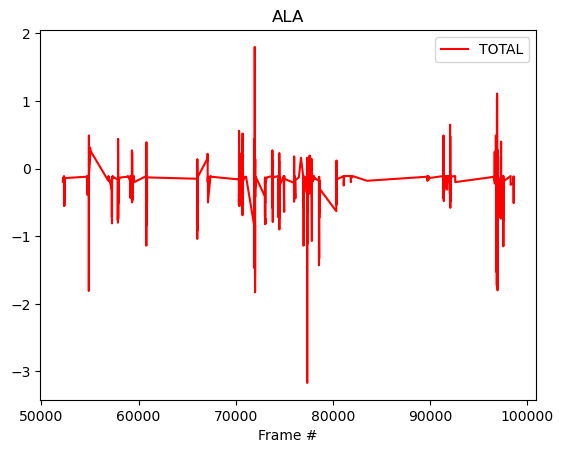

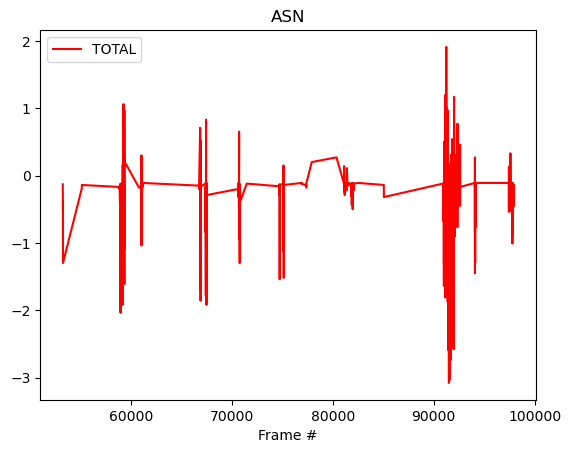

In [9]:
filtered_df1 = filter(df1)
df1_unique=filtered_df1['Residue'].unique().tolist()
df1_unique
window_size=2

for i in df1_unique:
   filtered_df1[(filtered_df1['Residue']==i)&((filtered_df1['TOTAL']<-0.1)|(filtered_df1['TOTAL']>0.1))].plot(x='Frame #',y='TOTAL',title=i,color='r')
  
    

In [10]:
filtered_df1[(filtered_df1['Residue']=='GLU')&(filtered_df1['TOTAL'])]

,Frame #,Residue,Residue Number,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL
3244,50036,GLU,634,0.0,-0.03,1.21,-1.03,-0.03,0.12
118337,51314,GLU,707,0.0,-0.02,1.38,-1.26,0.00,0.11
123737,51374,GLU,707,0.0,-0.03,-1.46,1.65,-0.03,0.12
123827,51375,GLU,707,0.0,-0.05,-0.47,0.66,-0.03,0.11
124547,51383,GLU,707,0.0,-0.05,-1.00,1.23,-0.04,0.14
...,...,...,...,...,...,...,...,...,...
4429358,99215,GLU,638,0.0,-0.23,1.17,-0.35,-0.07,0.52
4429448,99216,GLU,638,0.0,-0.18,-3.73,4.20,-0.13,0.15
4429628,99218,GLU,638,0.0,-0.22,-2.47,3.33,-0.19,0.45
4430258,99225,GLU,638,0.0,-0.02,1.55,-1.39,-0.00,0.12


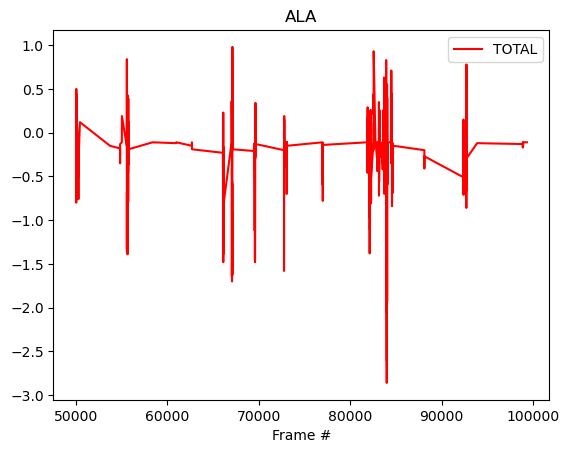

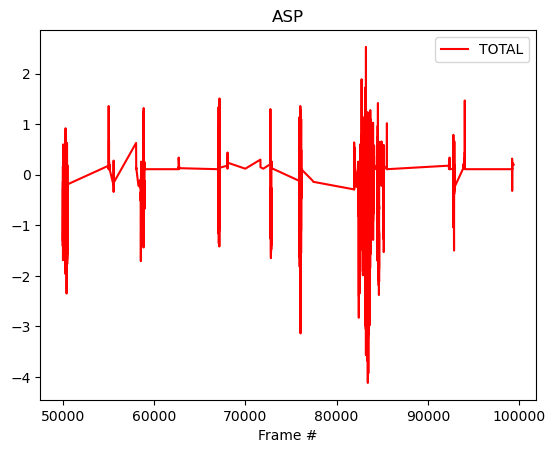

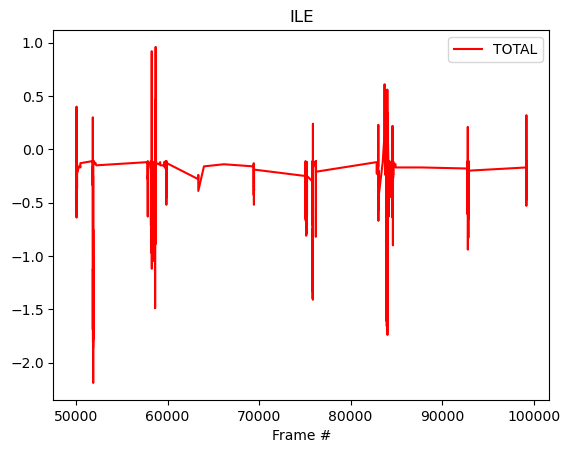

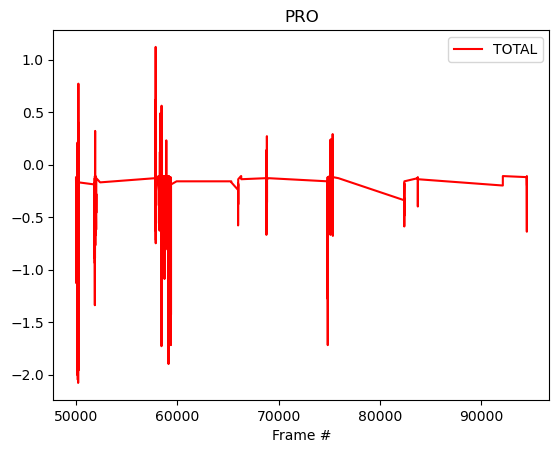

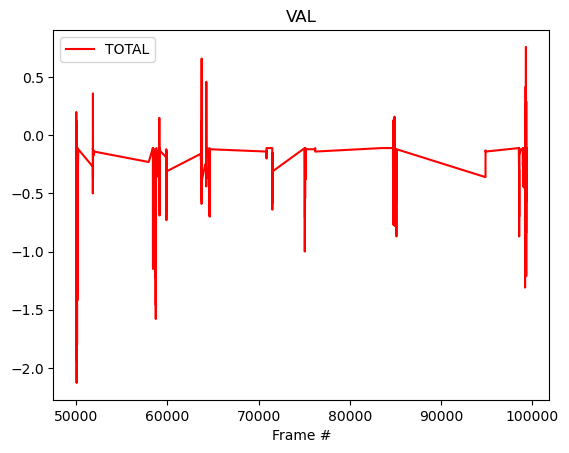

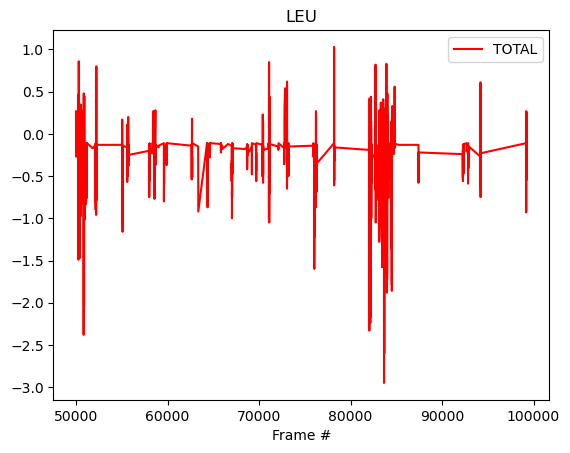

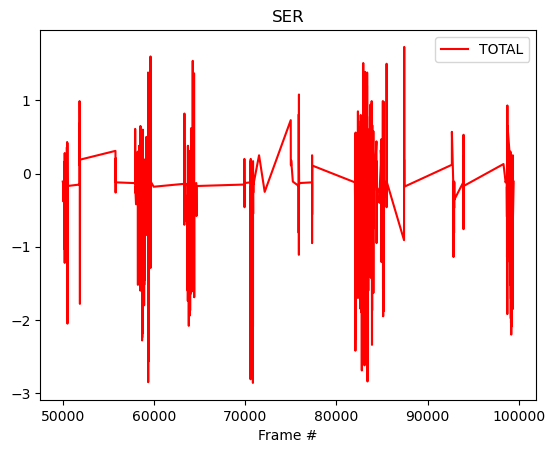

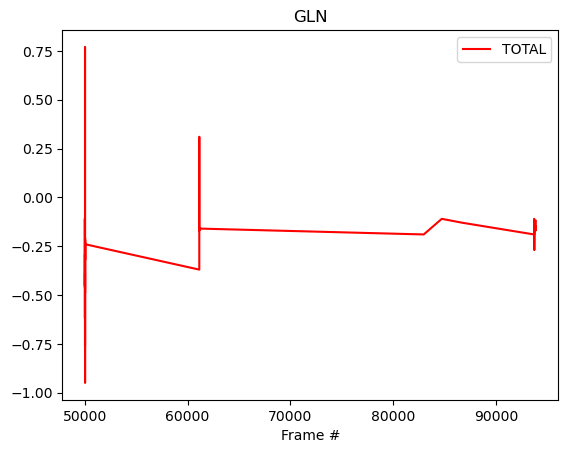

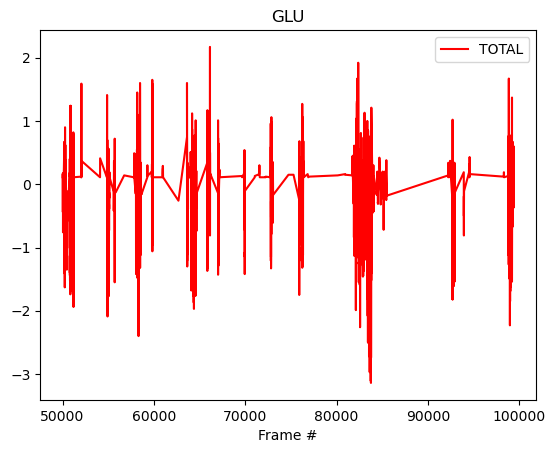

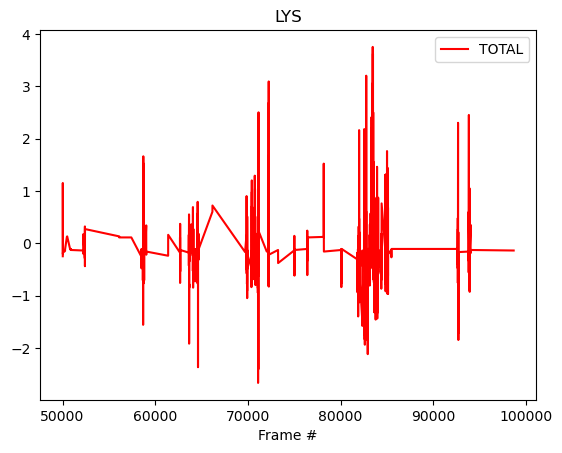

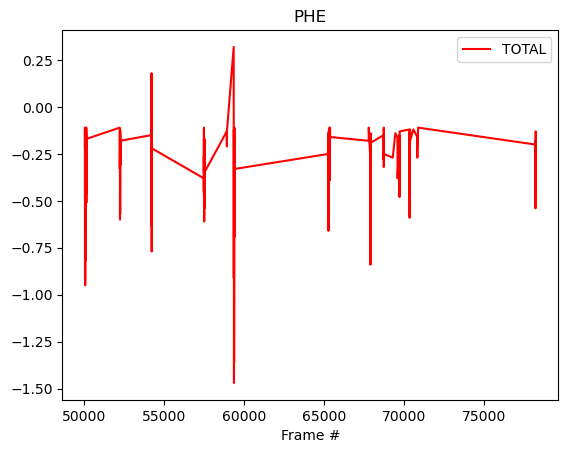

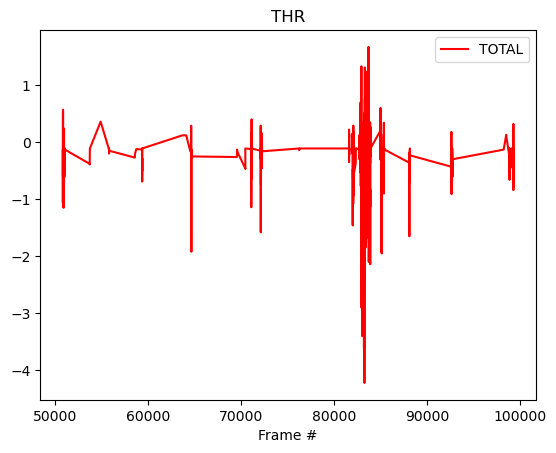

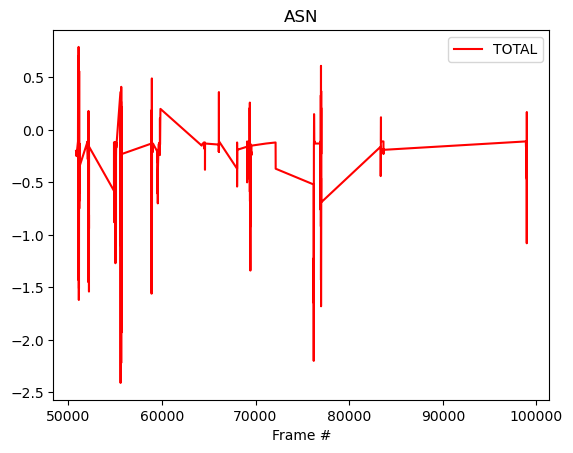

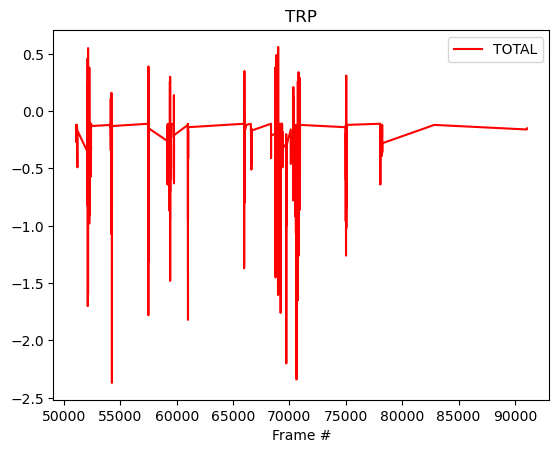

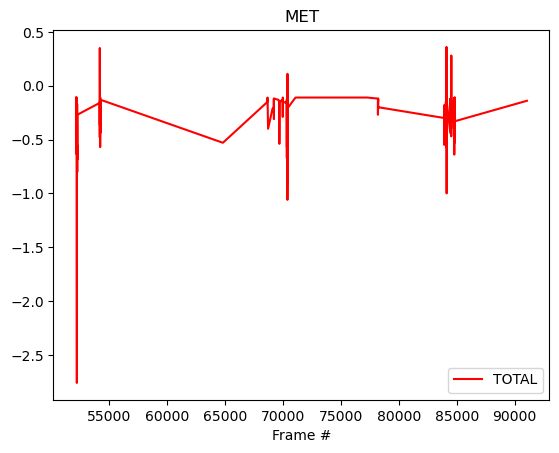

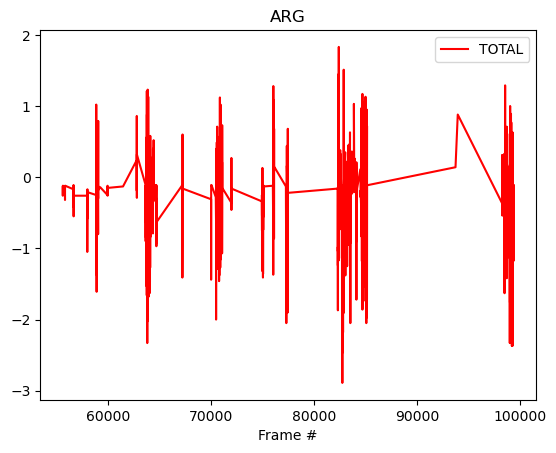

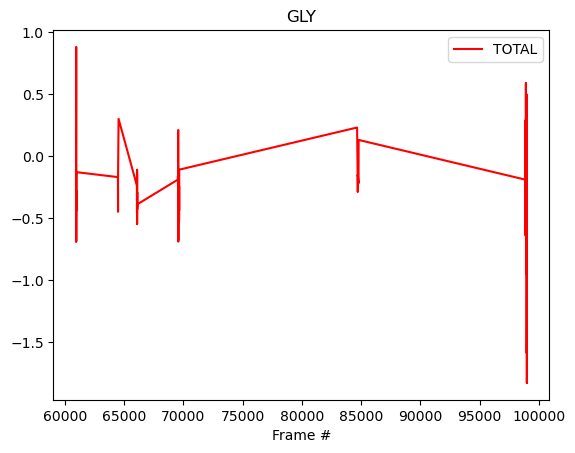

In [11]:
filtered_df2 = filter(df2)
df2_unique=filtered_df2['Residue'].unique().tolist()
for i in df2_unique:
    filtered_df2[(filtered_df2['Residue']==i)&((filtered_df2['TOTAL']<-0.1)|(filtered_df2['TOTAL']>0.1))].plot(x='Frame #',y='TOTAL',title=i,color='r')


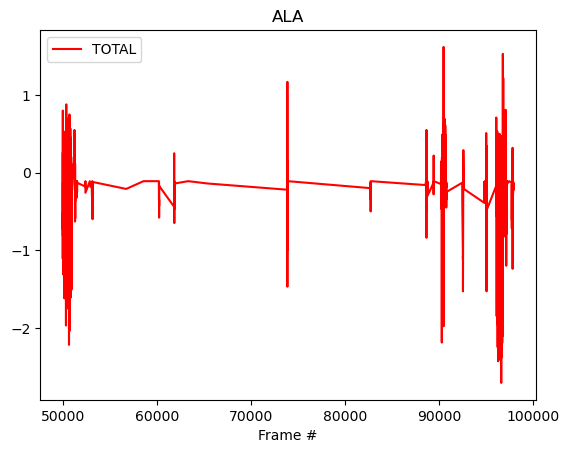

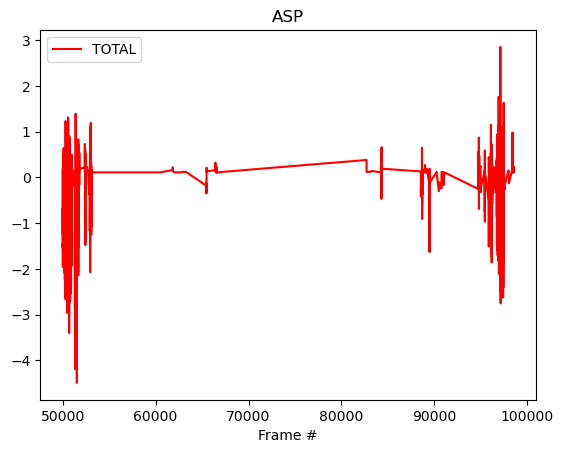

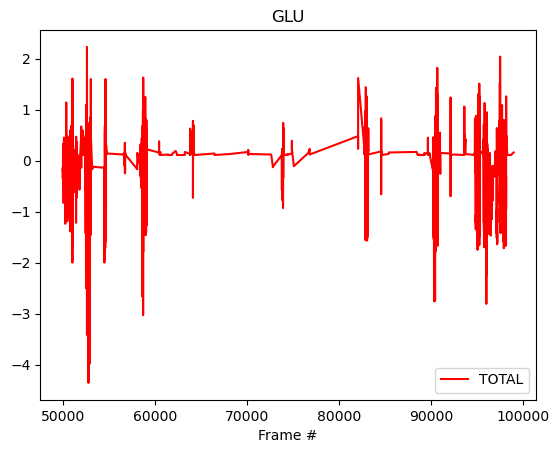

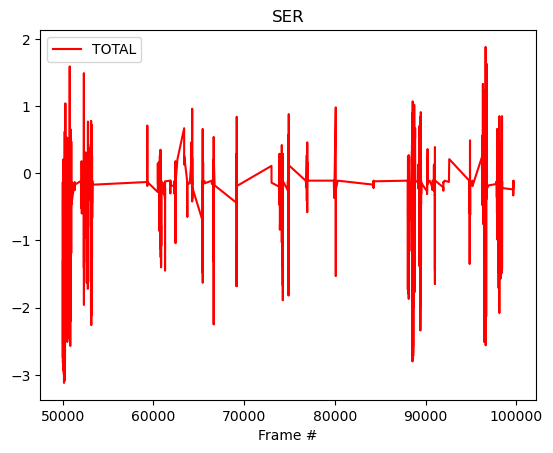

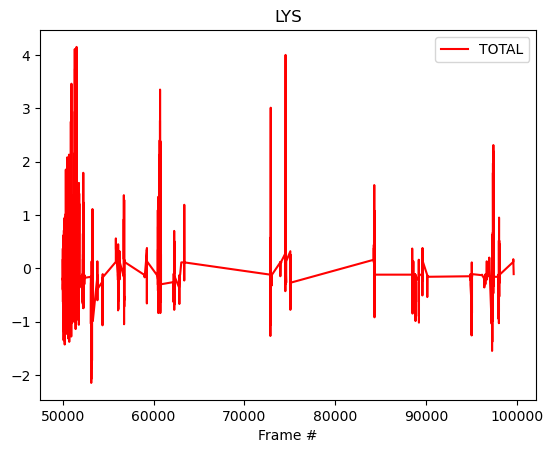

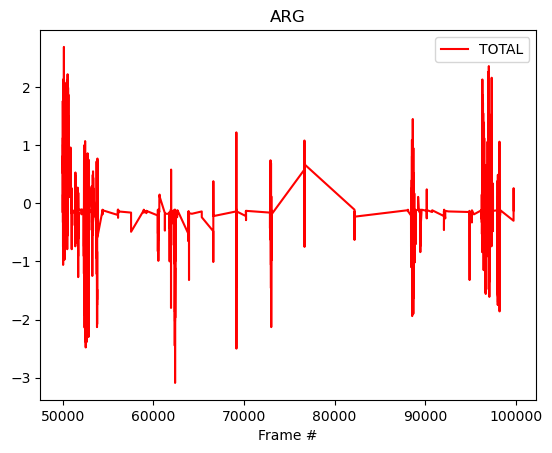

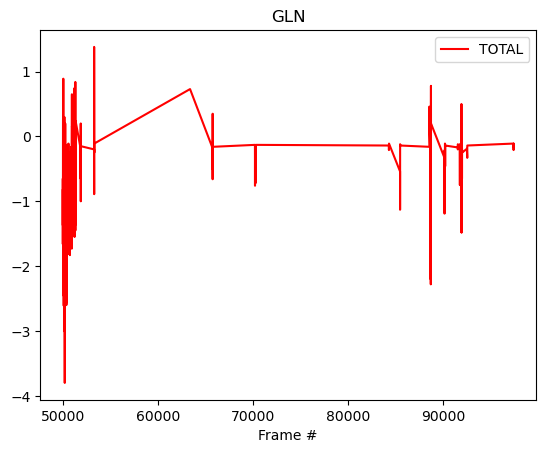

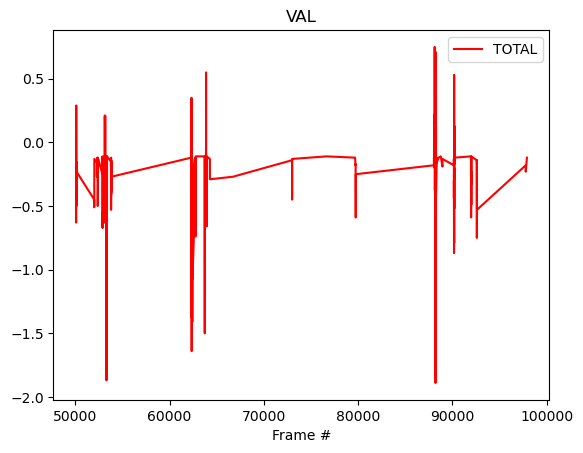

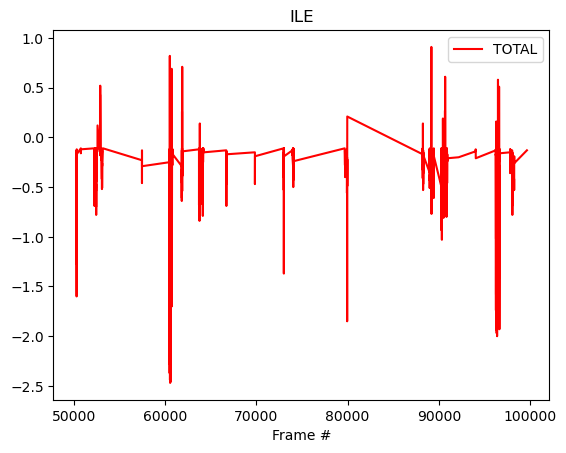

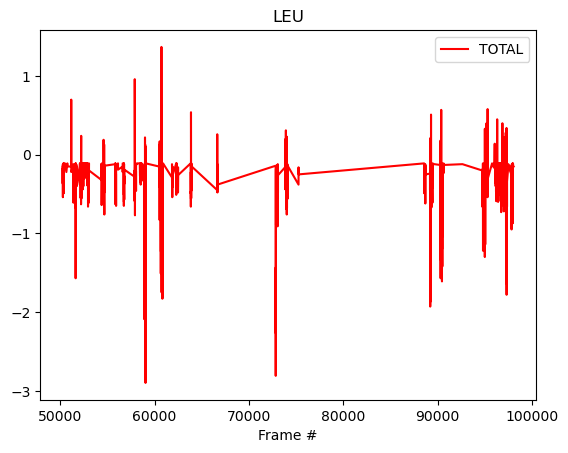

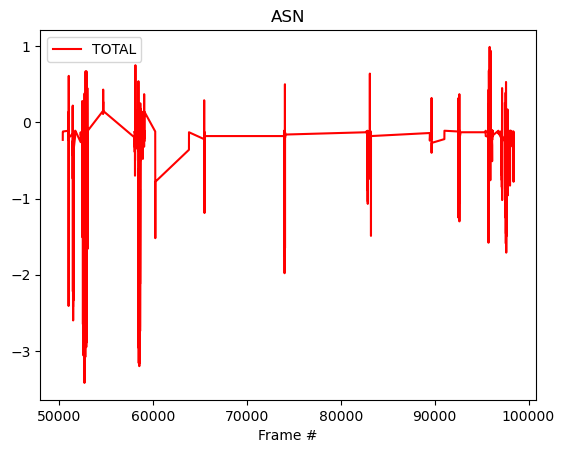

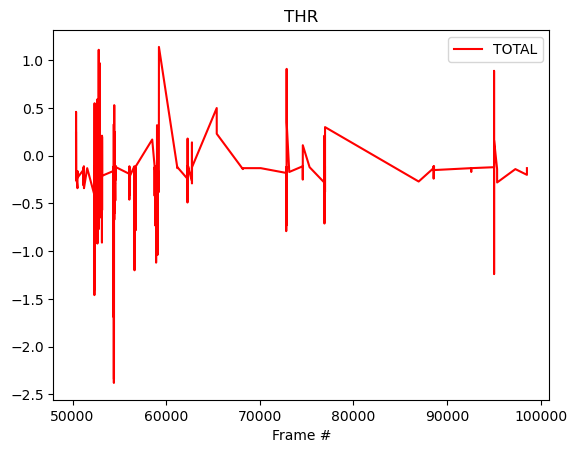

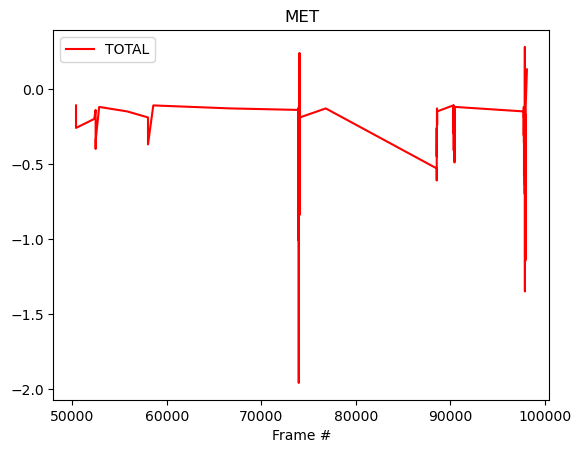

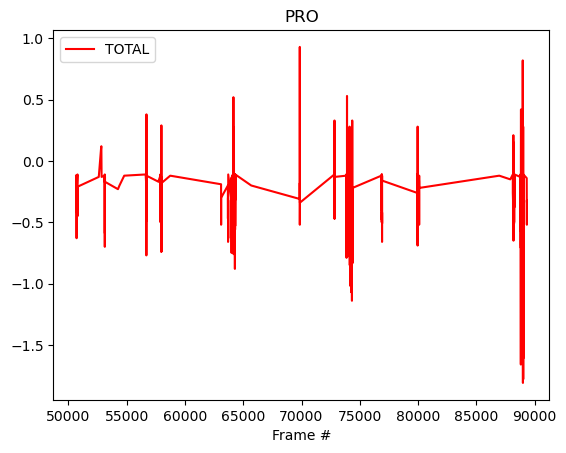

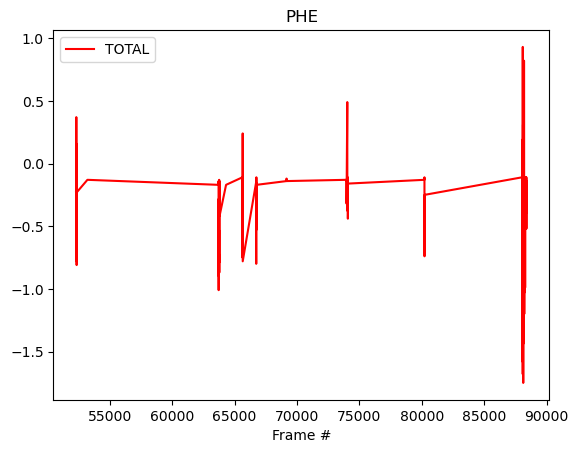

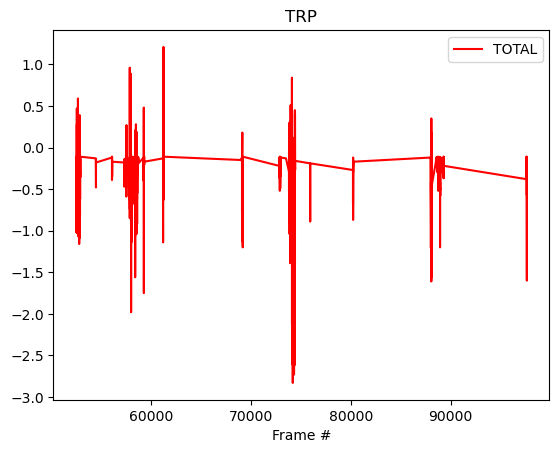

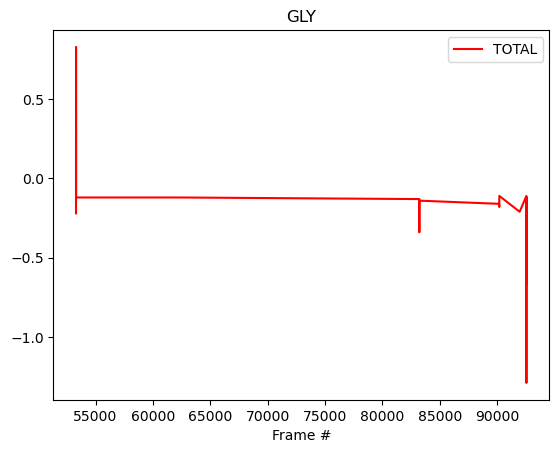

In [12]:
filtered_df3 = filter(df3)
df3_unique=filtered_df3['Residue'].unique().tolist()
for i in df3_unique:
    filtered_df3[(filtered_df3['Residue']==i)&((filtered_df3['TOTAL']<-0.1)|(filtered_df3['TOTAL']>0.1))].plot(x='Frame #',y='TOTAL',title=i,color='r')


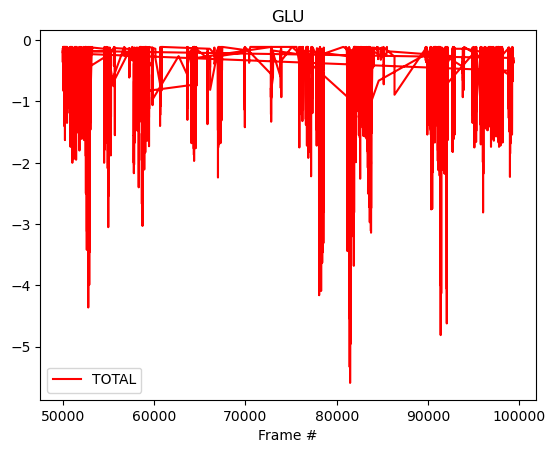

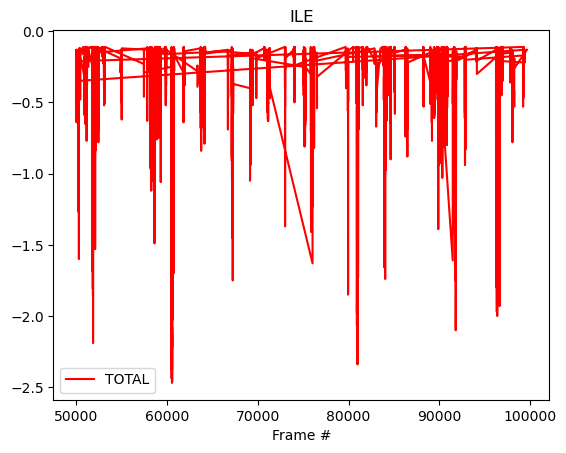

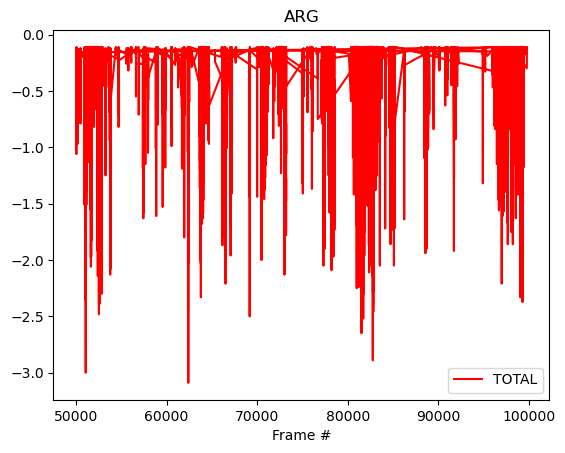

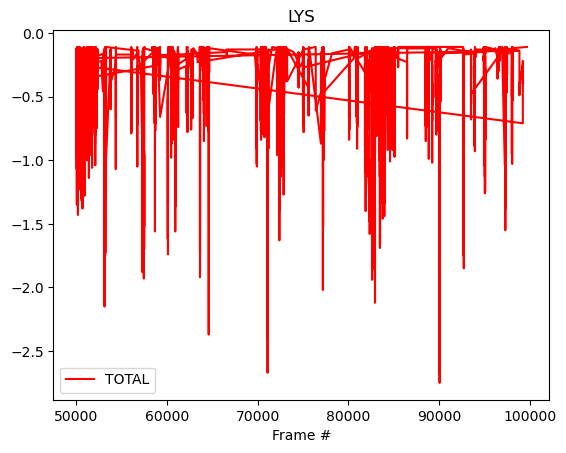

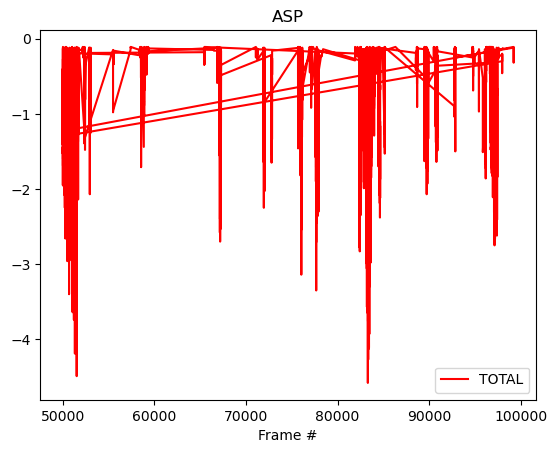

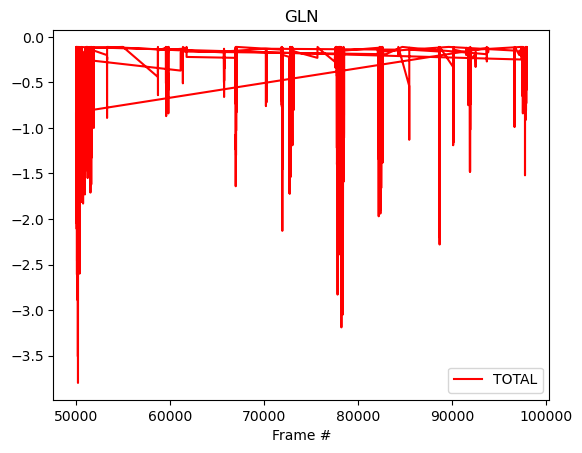

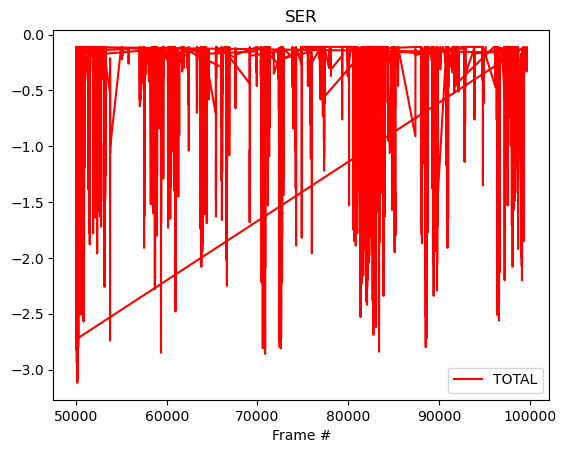

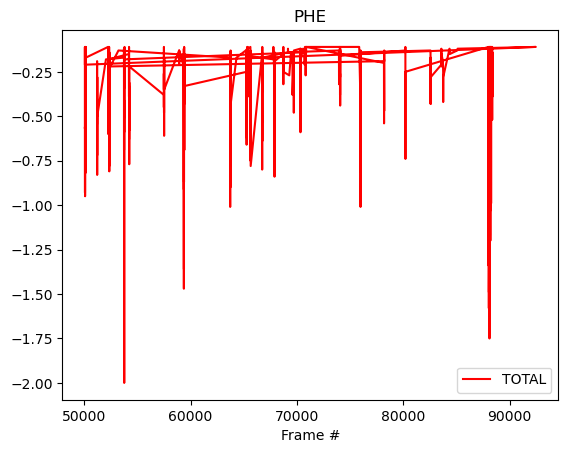

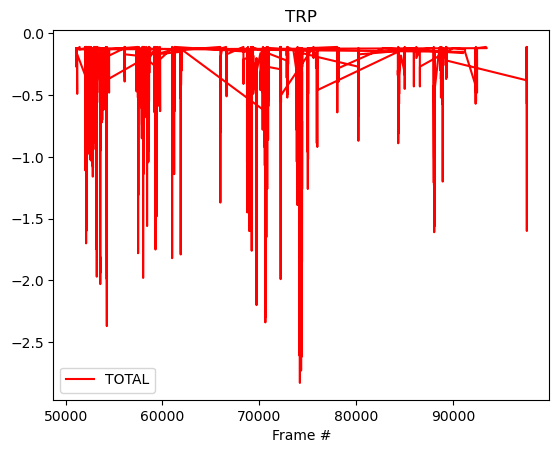

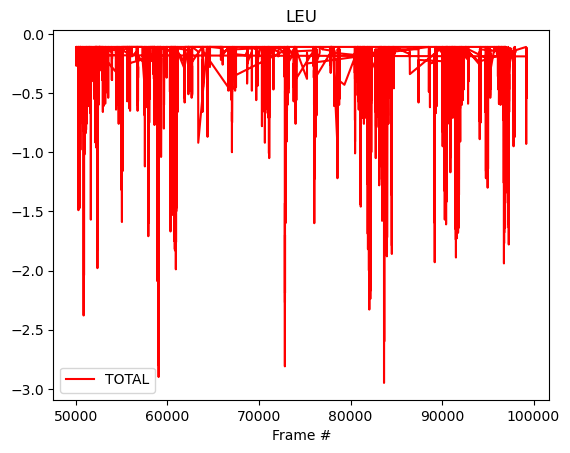

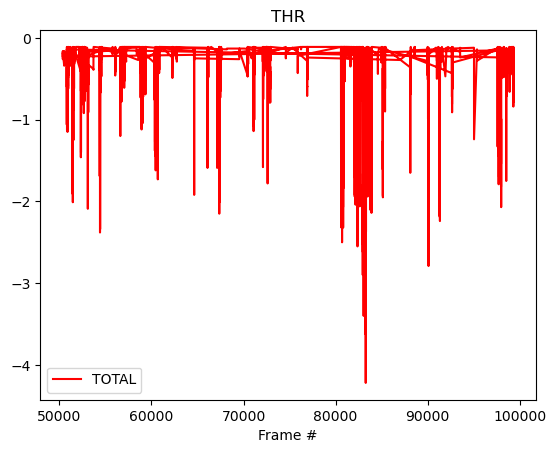

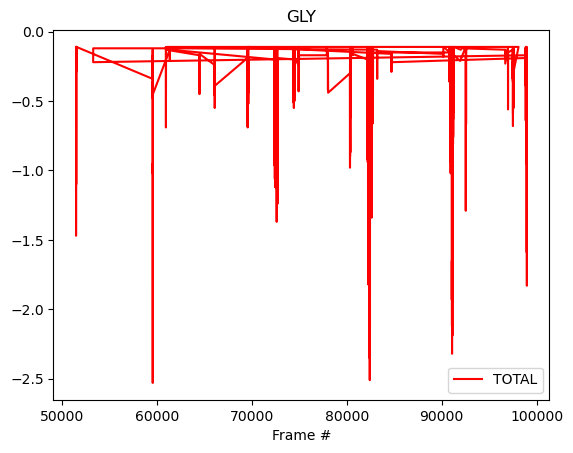

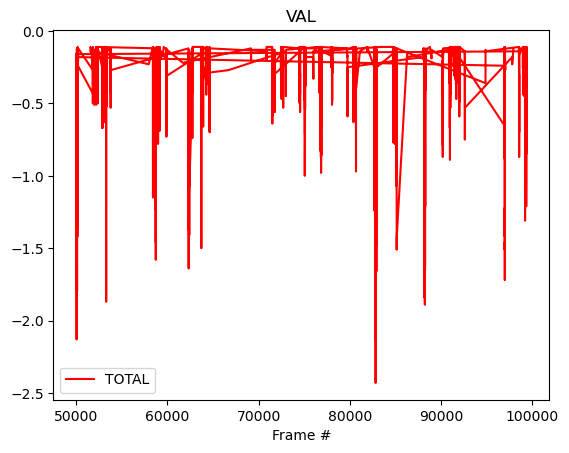

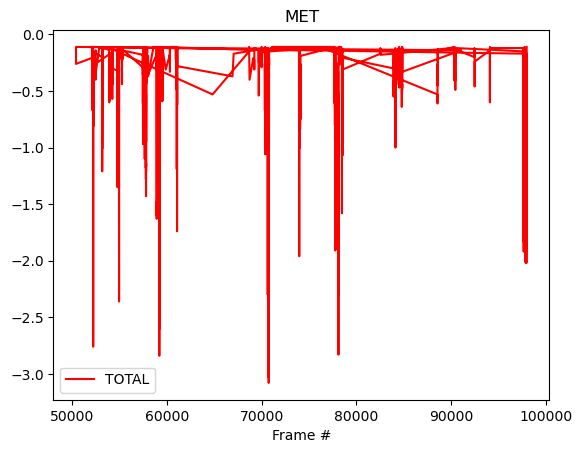

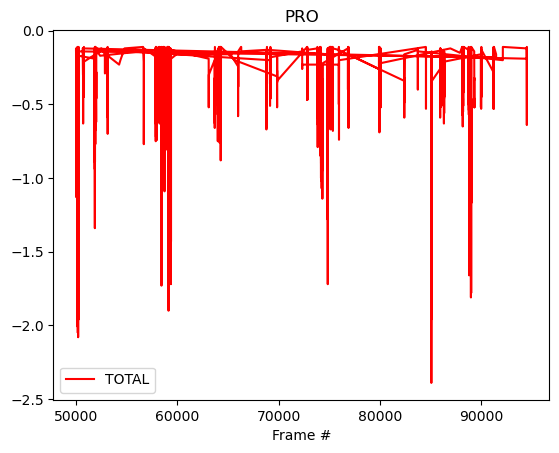

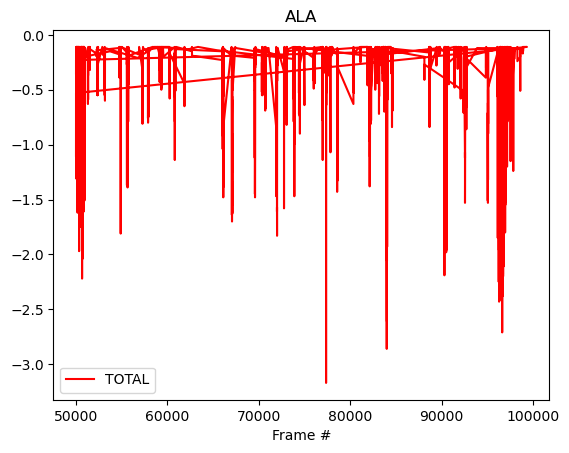

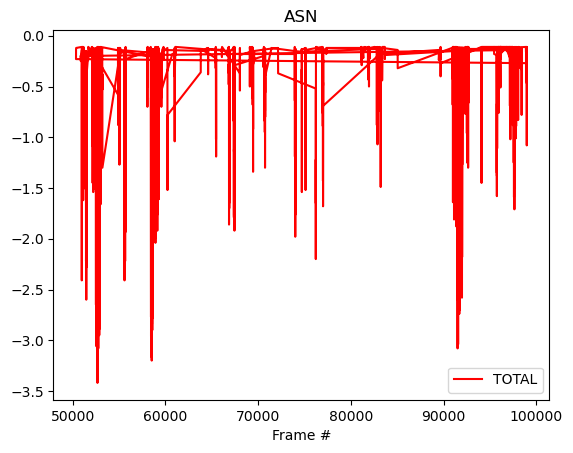

In [13]:
filtered_superdata = filter(superdata)
super_data = filtered_superdata['Residue'].unique().tolist()
for i in super_data:
    filtered_superdata[(filtered_superdata['Residue']==i)&(filtered_superdata['TOTAL']<0.0)].plot(x='Frame #',y='TOTAL',title=i,color='r')

In [14]:
filter(df1).sort_values(by='TOTAL', ascending=True)

,Frame #,Residue,Residue Number,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL
2831406,81460,GLU,636,0.0,0.71,-10.02,3.74,-0.02,-5.59
2827086,81412,GLU,636,0.0,0.98,-9.21,2.93,-0.02,-5.33
2833296,81481,GLU,636,0.0,1.79,-8.76,2.02,-0.01,-4.96
2828166,81424,GLU,636,0.0,1.25,-10.44,4.38,-0.04,-4.86
2836266,81514,GLU,636,0.0,0.80,-12.10,6.48,-0.04,-4.86
...,...,...,...,...,...,...,...,...,...
819292,59103,GLU,652,0.0,2.93,-7.22,7.45,-0.19,2.97
1834215,70380,LYS,645,0.0,1.45,-7.62,9.42,-0.27,2.98
4337734,98197,GLU,634,0.0,0.08,1.42,1.76,-0.25,3.01
1538139,67090,ARG,669,0.0,0.21,1.52,1.70,-0.16,3.26


# **SCATTER**

In [189]:
def scatter(data,run):
    data_sorted = filter(data).sort_values(by='TOTAL', ascending=True)
    x = data_sorted['TOTAL']
    Residue = data_sorted['Residue']
    unique_categories = Residue.unique()
    colors = plt.cm.get_cmap('hsv', len(unique_categories))
    plt.figure(figsize=(12, 8))
    for i, category in enumerate(unique_categories):
        plt.scatter(x[Residue == category], 
                    [i] * sum(Residue == category),
                    color=colors(i),s=3, 
                    label=category)
    plt.title(f"Scatter Plot for {run}")
    plt.xlabel('Total Energy')
    plt.ylabel('Amino Acids')
    plt.xlim([-4,0.5])
    plt.yticks(range(len(unique_categories)), unique_categories)
    plt.legend(title='Residue')
    plt.savefig(f"Scatter 1 H202_{run}.png", dpi=500)
    plt.show()


C:\Users\User\AppData\Local\Temp\ipykernel_3868\2338942573.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = plt.cm.get_cmap('hsv', len(unique_categories))


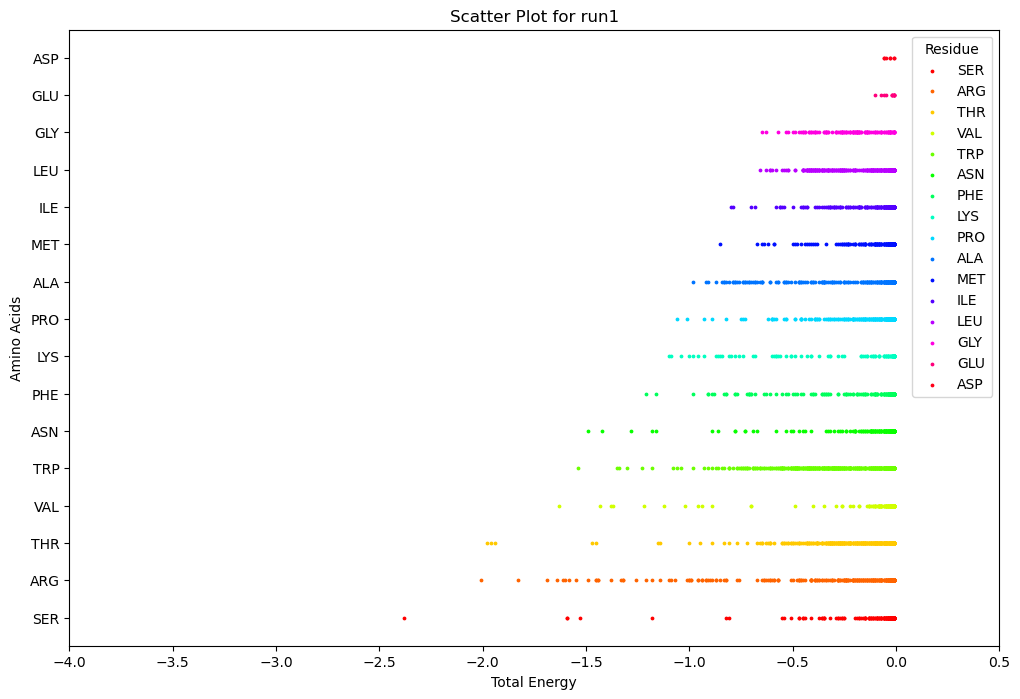

In [192]:
scatter(df1,'run1')

C:\Users\User\AppData\Local\Temp\ipykernel_3868\2338942573.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = plt.cm.get_cmap('hsv', len(unique_categories))


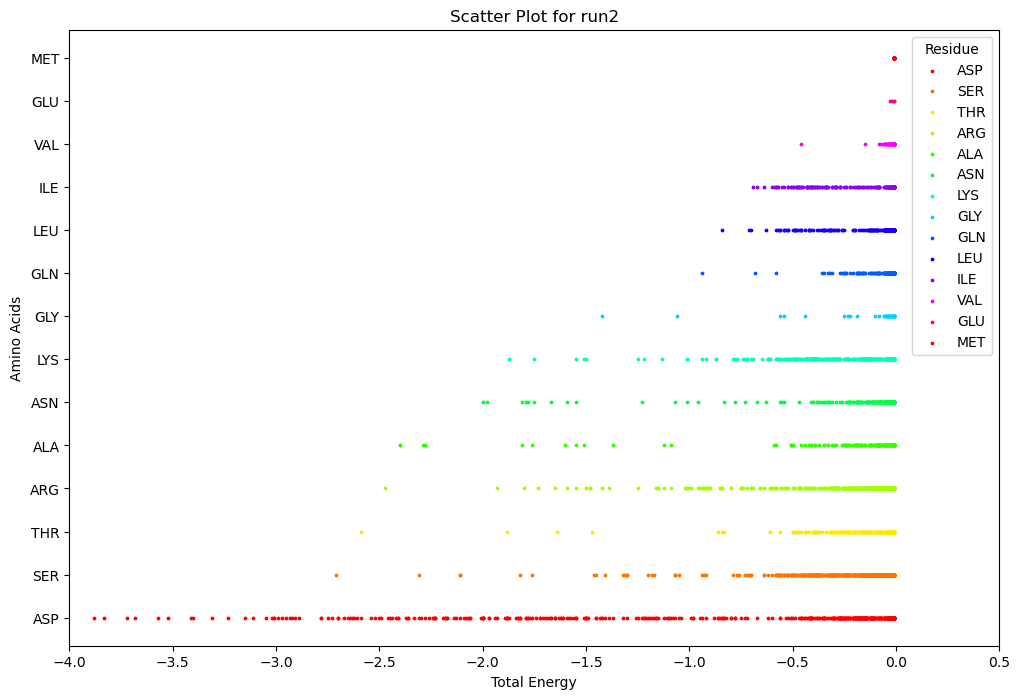

In [193]:
scatter(df2,'run2')

C:\Users\User\AppData\Local\Temp\ipykernel_3868\2338942573.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = plt.cm.get_cmap('hsv', len(unique_categories))


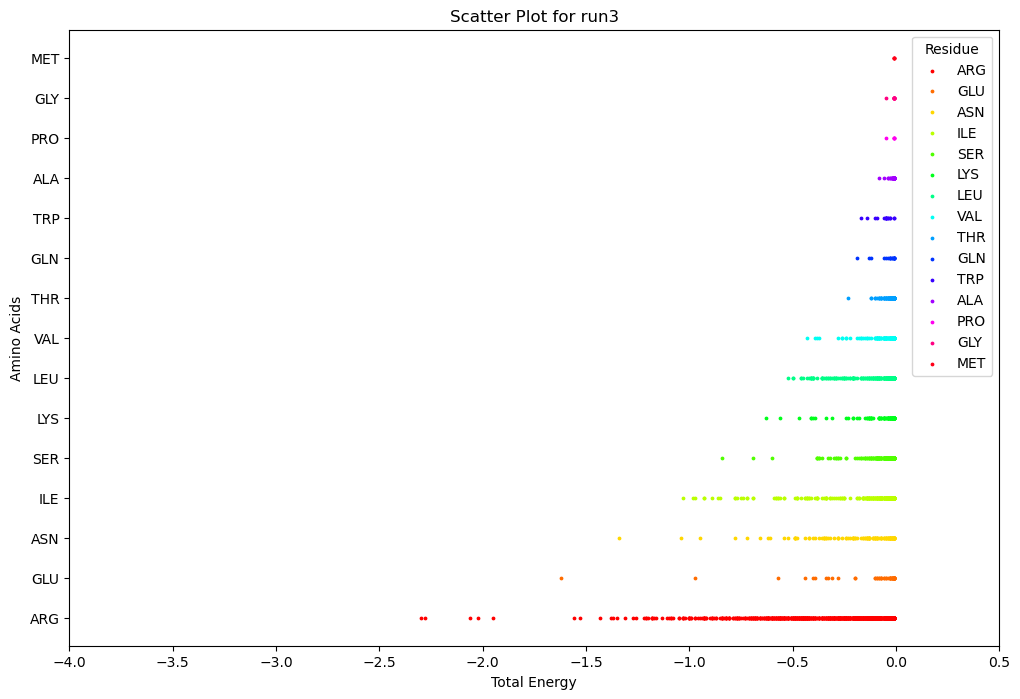

In [194]:
scatter(df3,'run3')

C:\Users\User\AppData\Local\Temp\ipykernel_3868\2338942573.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = plt.cm.get_cmap('hsv', len(unique_categories))


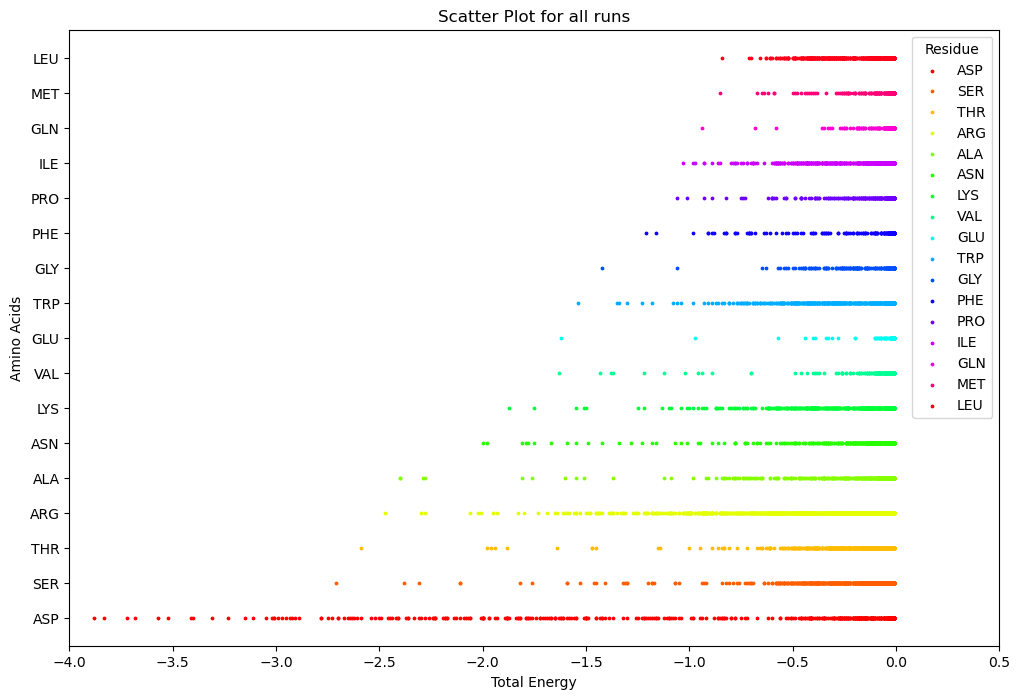

In [195]:
scatter(superdata,'all runs')

# **BAR CHART**

In [23]:
def mean_plot(data,run):
    mean_data = filter(data).groupby('Residue').mean().reset_index()
    mean_data['TOTAL'] = mean_data[['Internal', 'van der Waals', 'Electrostatic', 'Polar Solvation', 'Non-Polar Solv.']].sum(axis=1)
    residues = mean_data['Residue']
    totals = mean_data['TOTAL']
    internal = mean_data['Internal']
    van_der_Waals = mean_data['van der Waals']
    electrostatic = mean_data['Electrostatic']
    polar_solvation = mean_data['Polar Solvation']
    non_polar_solvation = mean_data['Non-Polar Solv.']
    colors = ['gray', 'lime', 'red', 'cyan', 'yellow']
    bar_width = 0.4
    indices = np.arange(len(residues))

    plt.figure(figsize=(14, 7))

    bar1 = plt.bar(indices, internal, bar_width, label='Internal', color=colors[0])
    bar2 = plt.bar(indices, van_der_Waals, bar_width, bottom=internal, label='van der Waals', color=colors[1])
    bar3 = plt.bar(indices, electrostatic, bar_width, bottom=internal + van_der_Waals, label='Electrostatic', color=colors[2])
    bar4 = plt.bar(indices, polar_solvation, bar_width, bottom=internal + van_der_Waals + electrostatic, label='Polar Solvation', color=colors[3])
    bar5 = plt.bar(indices, non_polar_solvation, bar_width, bottom=internal + van_der_Waals + electrostatic + polar_solvation, label='Non-Polar Solv.', color=colors[4])

    plt.plot(indices, totals, 'o', color='black', label='TOTAL', markersize=8)

    plt.xlabel('Amino acid')
    plt.ylabel('Total Energy')
    plt.ylim([-4,0.5])
    plt.title(f"Mean Energy for Each Amino Acid {run}")
    plt.xticks(indices, residues, rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"residue_means_10 H202_{run}.png", dpi=500)
    plt.show()

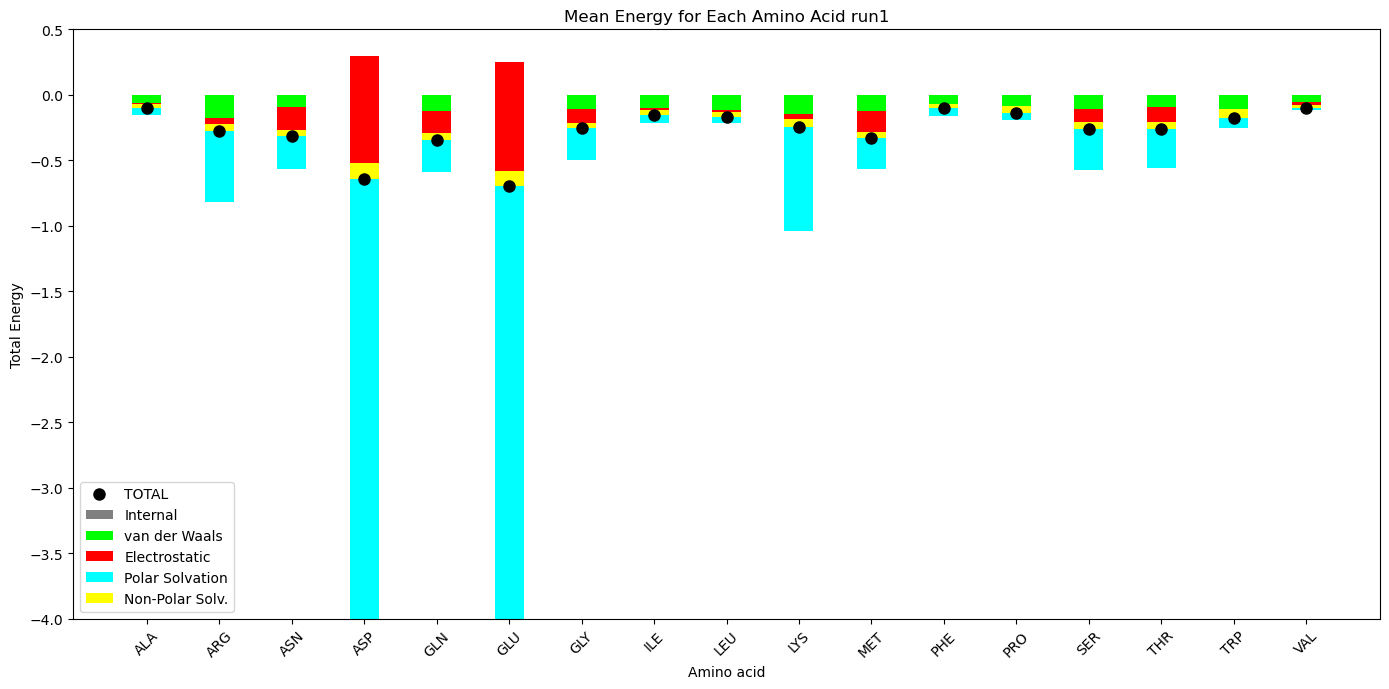

In [25]:
mean_plot(df1,'run1')

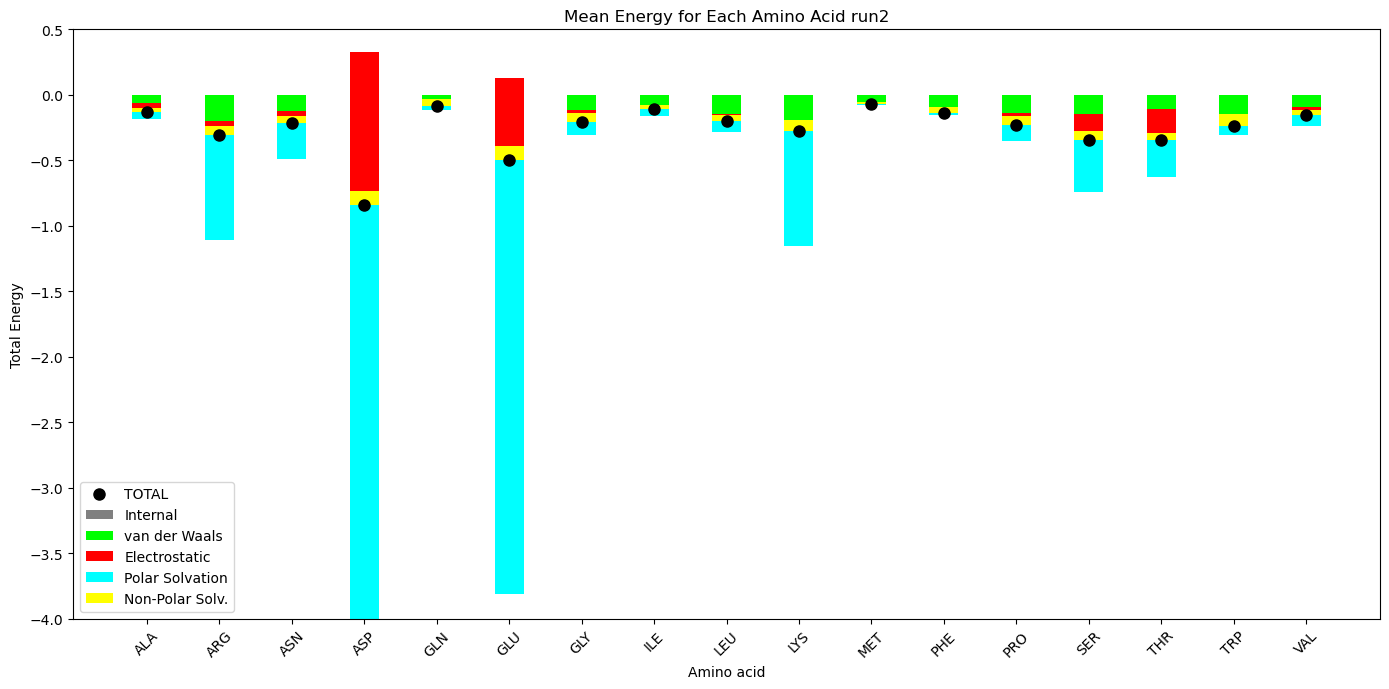

In [27]:
mean_plot(df2,'run2')

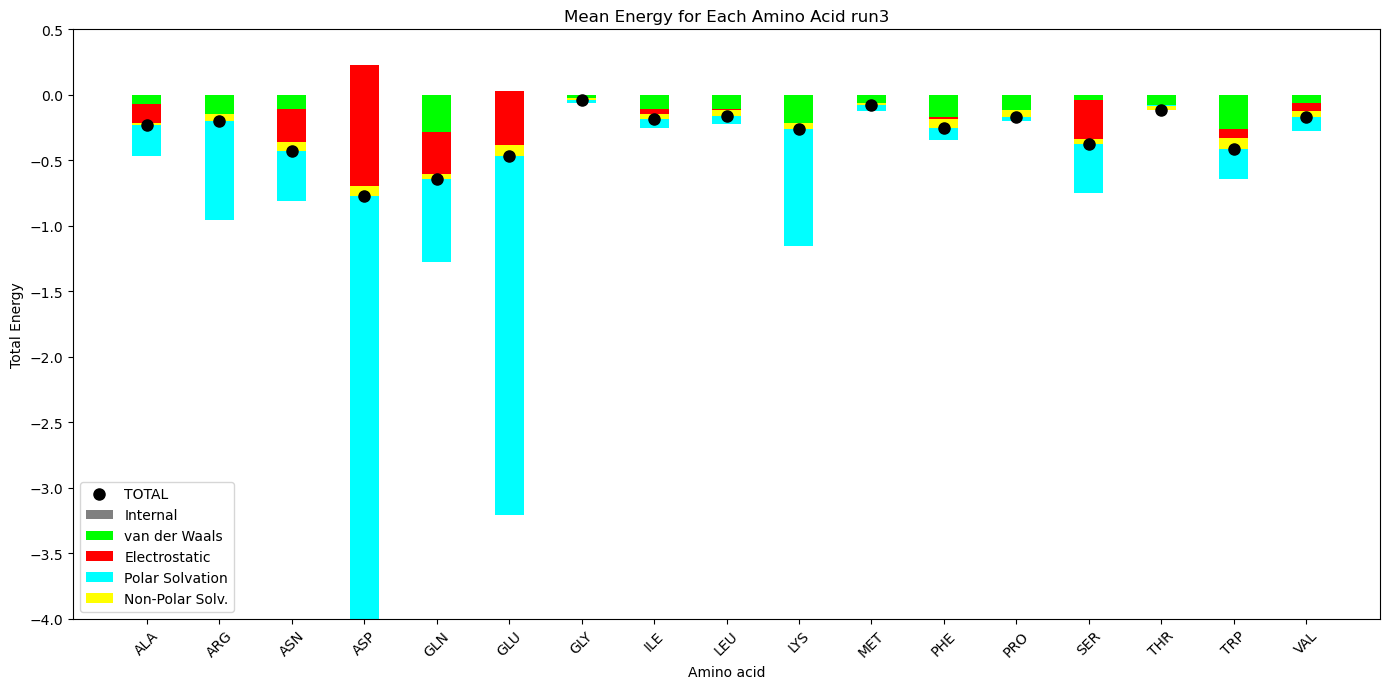

In [29]:
mean_plot(df3,'run3')

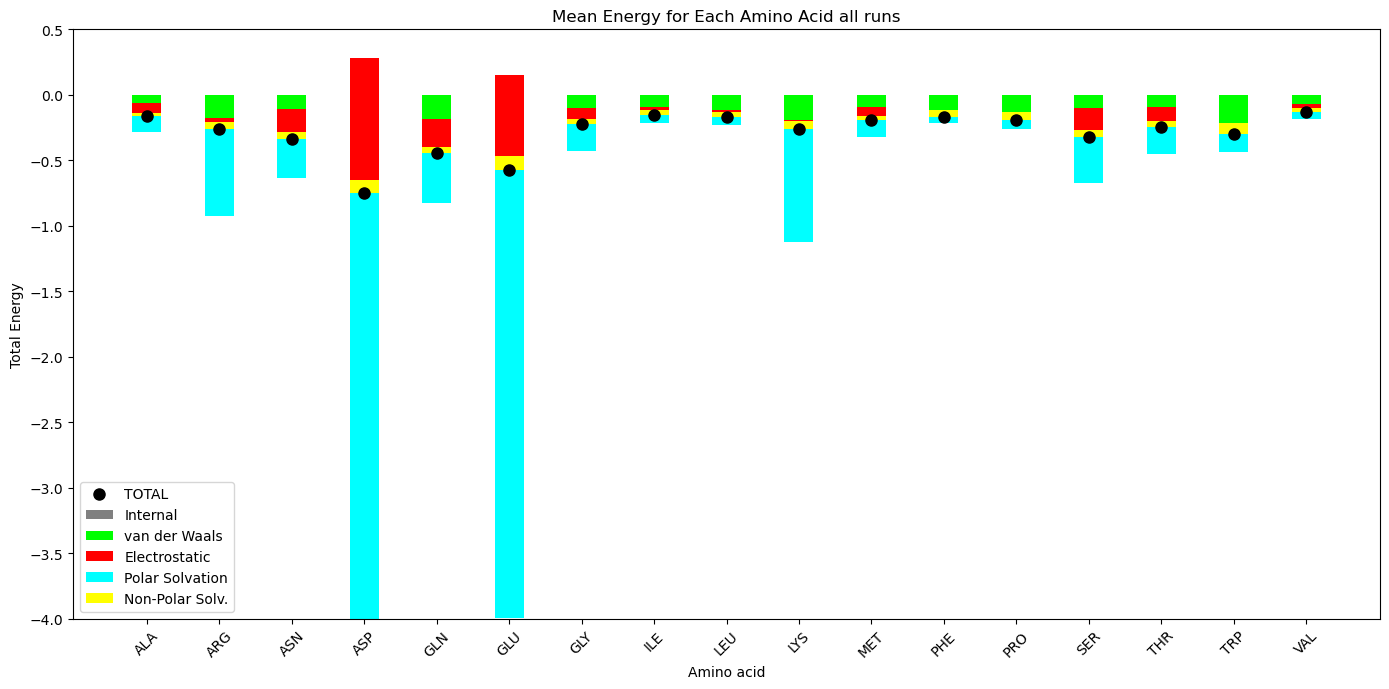

In [31]:
mean_plot(superdata,'all runs')